In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("../data/sign_mnist_train.csv")
test = pd.read_csv("../data/sign_mnist_test.csv")

print("Train :", train.shape)
print("Test  :", test.shape)
train.head()

Train : (27455, 785)
Test  : (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [3]:
print("Valeurs manquantes (train) :", train.isnull().sum().sum())
print("Valeurs manquantes (test)  :", test.isnull().sum().sum())
print("Doublons (train) :", train.duplicated().sum())

pixels = train.drop(columns="label")
print("Pixel min / max :", pixels.values.min(), pixels.values.max())
print("Labels train :", sorted(train["label"].unique()))
print("Labels test  :", sorted(test["label"].unique()))

Valeurs manquantes (train) : 0
Valeurs manquantes (test)  : 0
Doublons (train) : 0
Pixel min / max : 0 255
Labels train : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Labels test  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


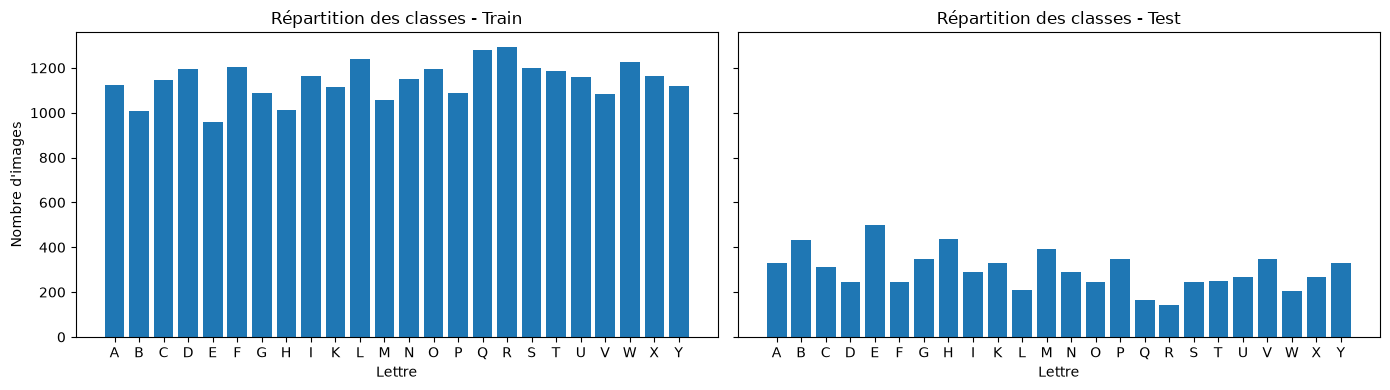

count      24.000000
mean     1143.958333
std        83.758701
min       957.000000
25%      1089.500000
50%      1156.000000
75%      1196.750000
max      1294.000000
Name: count, dtype: float64


In [4]:
label_to_letter = {l: chr(65 + l) for l in range(25) if l != 9}

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, df, name in zip(axes, [train, test], ["Train", "Test"]):
    counts = df["label"].value_counts().sort_index()
    ax.bar([label_to_letter[l] for l in counts.index], counts.values)
    ax.set_title(f"Répartition des classes - {name}")
    ax.set_xlabel("Lettre")
axes[0].set_ylabel("Nombre d'images")
plt.tight_layout()
plt.show()

print(train["label"].value_counts().describe())

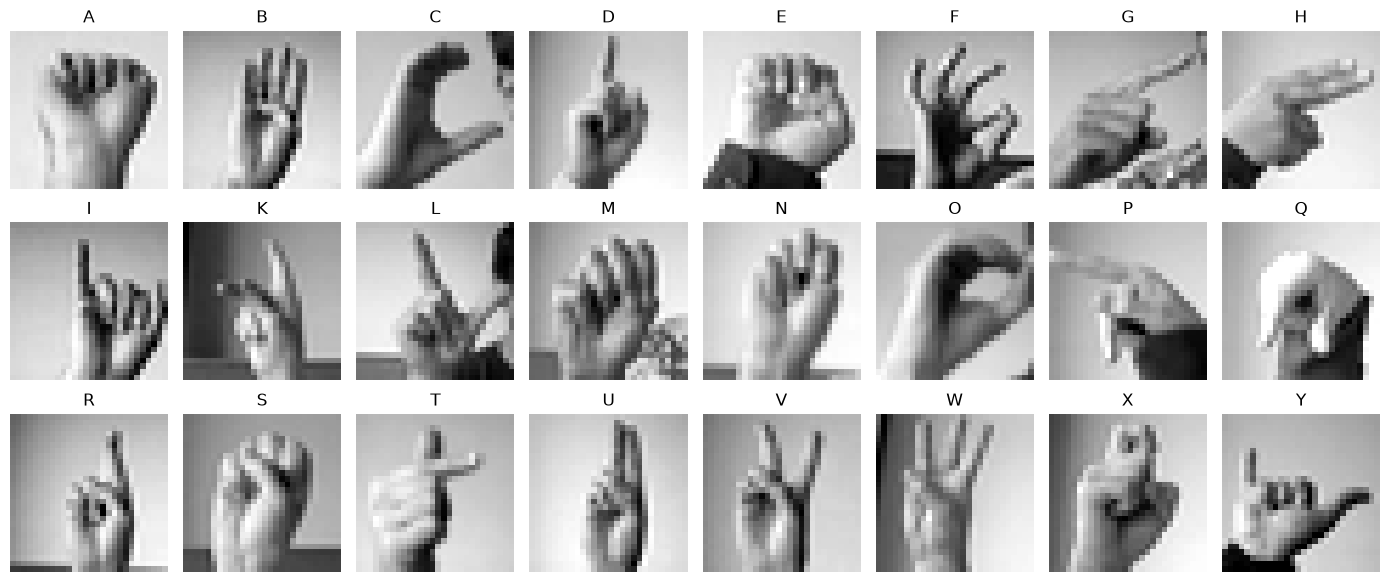

In [5]:
def to_img(row):
    return row.values.reshape(28, 28)

# Un exemple par lettre
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax, (label, letter) in zip(axes.ravel(), label_to_letter.items()):
    sample = train[train["label"] == label].iloc[0].drop("label")
    ax.imshow(to_img(sample), cmap="gray")
    ax.set_title(letter)
    ax.axis("off")
plt.tight_layout()
plt.show()

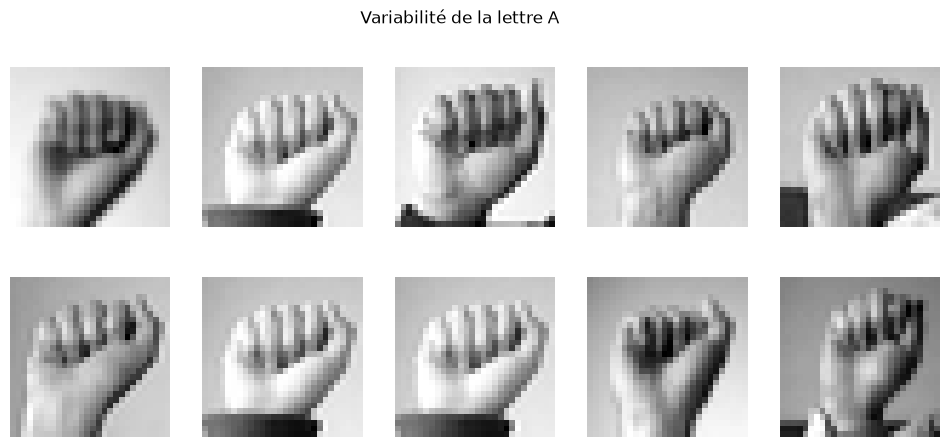

In [6]:
# Plusieurs exemples d'une même lettre pour voir la variabilité
letter_label = 0  # A
subset = train[train["label"] == letter_label].sample(10, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (_, row) in zip(axes.ravel(), subset.iterrows()):
    ax.imshow(to_img(row.drop("label")), cmap="gray")
    ax.axis("off")
plt.suptitle(f"Variabilité de la lettre {label_to_letter[letter_label]}")
plt.show()

Moyenne globale : 159.3
Écart-type global : 48.8


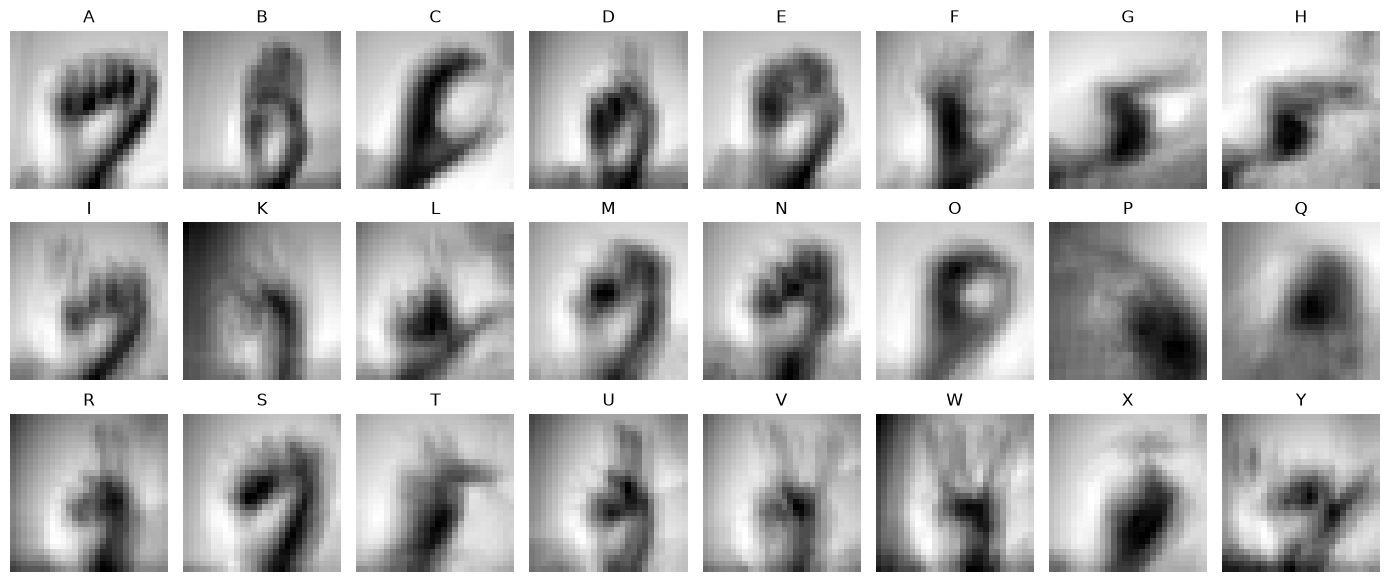

In [7]:
print("Moyenne globale :", pixels.values.mean().round(1))
print("Écart-type global :", pixels.values.std().round(1))

# Image moyenne par lettre
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax, (label, letter) in zip(axes.ravel(), label_to_letter.items()):
    mean_img = train[train["label"] == label].drop(columns="label").mean().values.reshape(28, 28)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(letter)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
train_hashes = set(map(tuple, train.drop(columns="label").values))
test_hashes = [tuple(r) for r in test.drop(columns="label").values]
overlap = sum(h in train_hashes for h in test_hashes)
print(f"Images du test identiques à une image du train : {overlap} / {len(test)}")

Images du test identiques à une image du train : 0 / 7172


In [9]:
# Remapper les labels (0..24 sans 9) vers 0..23
classes = sorted(train["label"].unique())
label_map = {old: new for new, old in enumerate(classes)}
idx_to_letter = {new: label_to_letter[old] for old, new in label_map.items()}

y_train = train["label"].map(label_map).values
y_test = test["label"].map(label_map).values

# Images en (N, 28, 28, 1), normalisées entre 0 et 1
X_train = train.drop(columns="label").values.reshape(-1, 28, 28, 1).astype("float32") / 255.0
X_test = test.drop(columns="label").values.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print(idx_to_letter)

# Sauvegarde pour les notebooks suivants
np.savez_compressed("../data/sign_mnist_prepared.npz",
                    X_train=X_train, y_train=y_train,
                    X_test=X_test, y_test=y_test)

import json
with open("../data/idx_to_letter.json", "w") as f:
    json.dump(idx_to_letter, f)

(27455, 28, 28, 1) (27455,) (7172, 28, 28, 1) (7172,)
{0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 9: 'K', 10: 'L', 11: 'M', 12: 'N', 13: 'O', 14: 'P', 15: 'Q', 16: 'R', 17: 'S', 18: 'T', 19: 'U', 20: 'V', 21: 'W', 22: 'X', 23: 'Y'}
